<a href="https://colab.research.google.com/github/JulTob/Optimization/blob/main/Practicas/P2/Lecci%C3%B3n_Pr%C3%A1ctica_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#@title <font color="steelblue" size="+1"> Ejecutar configuración
!pip install cplex
!pip install docplex
!pip install yfinance
!pip install PyPortfolioOpt

from pypfopt import expected_returns
from pypfopt import risk_models
from pypfopt import EfficientFrontier
from docplex.mp.model import Model
from docplex.mp.environment import Environment
env = Environment()
env.print_information()

import numpy as np
import matplotlib.pyplot as plt
from imageio import imread

import statistics as st
import matplotlib.pyplot as plt
from scipy.stats import norm
import numpy as np  # always need it
import pylab as pl  # do the plots
import time


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.2/52.2 MB 42.1 MB/s  0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.0/664.0 kB 9.1 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for docplex: filename=docplex-2.32.264-py3-none-any.whl size=703859 sha256=8dc97c5385f1236ab7decb89b1cca9c29af901fcaa0a59e58bf018a097e47342
  Stored in directory: /root/.cache/pip/wheels/ba/11/de/5d0051be010658975fb2155006b4b8a818136d9f69ed20b4ba
Successfully built docplex
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [PyPortfolioOpt]
* system is: Linux 64bit
* Python version 3.13.18, located at: /usr/bin/python3
* docplex is present, version is 2.32.264
* CPLEX library is present, version is 22.2.0.0, located at: /usr/local/lib/python3.13/dist-packages
* pandas is present, version is 2.2.3


## <font color="steelblue">**Lección Práctica 2**</font>

Problemas de optimización con funciones cuadráticas. Maximizar (Minimizar) una función cuadrática con restricciones lineales.

Una función cuadrática en varias variables puede representarse del siguiente modeo:

$$𝑥^𝑇𝑄𝑥$$

donde, $𝑥=(𝑥_1,𝑥_2,...,𝑥_𝑛)$ es el vector de variables y $𝑄$ es una matriz cuadrada de orden $𝑛\cdot𝑛$.

Si la matriz $𝑄$ es definida positiva, entonces la función $𝑥^𝑇𝑄𝑥$ es una función convexa, y por lo tanto, el problema

$$\min 𝑥^𝑇𝑄𝑥$$

si tiene un mínimo, entonces ese mínimo es global. (Análogamente si $𝑄$ es definida negativa, entonces si el problema $\max 𝑥^𝑇𝑄𝑥$ presenta un máximo, este máximo es un máximo global)



<font color="steelblue">**Programación cuadrática con restricciones lineales**</font>    

Un caso particular de programación cuadrática es el siguiente:

$\min \quad c^t x + \frac{1}{2}x^TQx$

$s.t.$

$Ax=b$

    
##<font color="steelblue">**Ejemplo**</font>    
    
El problema clásico  de optimización de una cartera (**Markowitz**) se define del siguiente modo:
    
$\min  x^T \Sigma x$

$s.t.$

$\mu^T x \geq \delta $  
    
$e^T x = 1$

$x\geq 0,$
    
donde $\Sigma$ es la matriz de covarianzas entre los activos a considerar en la cartera, $\mu$ es el vector de retornos esperados de cada activo, y $\delta$ es la rentabilidad media esperada  por nuestra cartera.  

Notar que el vector $e^T=(1,1,\cdots,1)$, y el vector $x=(x_1,x_2,\cdots,x_n)$ es el vector de variables de decisión, donde la variable $x_i$ representa la fracción de mi capital a invertir en el título $i$.    
    
Supongamos que tenemos 5 activos disponibles para realizar nuestra inversión, con los siguientes datos:
    
$\mu^T=(2,3,1,5,6)$    

$\Sigma =
\begin{pmatrix}
9 & 0 & 0 & 0 & -1\\
0 & 8 & 0 & -1 & 0\\
0 & 0 & 8 & -2 & -2 \\
0 & -1 & -2 & 8 & 0 \\
-1 & 0 & -2 & 0 & 9
\end{pmatrix}
$     
  
   
    
    
$\delta= 4$    
    

In [1]:
#@title <font color="steelblue" size="+1"> Ejemplo CPLEX
mu=[2,3,1,5,6]
Sigma=[ [ 9, 0, 0, 0,-1],
        [ 0, 8, 0,-1, 0],
        [ 0, 0, 8,-2,-2],
        [ 0,-1,-2, 8, 0],
        [-1, 0,-2, 0, 9]]
delta = 4
N = range(len(mu))

# Modelo
mdl = Model()

# Variables
x_vars = [mdl.continuous_var(lb=0, ub=1, name=None ) for i in N]

# Restricciones
mdl.add_constraint( mdl.sum( mu[i]*x_vars[i] for i in N) >= delta )
# Objective
mdl.minimize(mdl.sum(   Sigma[i][j] * x_vars[i]*x_vars[j]  for i in N for j in N) )
# s = mdl.solve(log_output=True)
s = mdl.solve()
obj = mdl.objective_value
for i in N:
    print(" La variable x{} toma el valor {}".format(i,x_vars[i].solution_value))
print("* best objective is: {:g}".format(obj))

NameError: name 'Model' is not defined



---

## <font color="steelblue">**Ejemplo**:</font>

(https://inst.eecs.berkeley.edu/~ee127/sp21/livebook/l_socp_apps_tv.html)



 The localization problem    
    
We are given anchor positions $x_i \in \mathbf{R}^3$, and associated distances from these anchor points to an unknown object, $R_i$, $i=1,\ldots,m$.
    
    
The problem is to estimate a position of the object, and associated measure of uncertainty around the estimated point.
    
Geometrically, the measurements imply that the object is located at the intersection of the m spheres of centers $x_i$ and radiuses $R_i$, $i=1,\ldots,m$.
    
The main problem is to provide one point in the intersection located at some kind of ‘‘center’’, and also a measure of the size of the intersection.



    


<blockquote>

<font color="steelblue">**Definición**:</font>

Deseamos inferir la posicición de un objeto en el espacio con la mayor precisión posible, disponiendo de una serie de medidas de rango.
    
Un caso particular es la determinación de un usuario de telefonía movil a partir de la intensidad de señal recibida por un conjunto de antenas  o estaciones base.

</blockquote>





<span style="color:blue">
    
El problema de localización con tres medidas en dos dimensiones, con datos

$ X = (x_1,x_2,x_3) =
\left(\begin{array}{ccc}-0.46&0.19&0.48 \\
0.03&0.54&-0.49 \end{array}\right)$

$   
R^T = (R_1,R_2,R_3)= (0.5 ,  0.6 ,0.85)$

    
El objetivo es encontrar el **centro** del area de intersección, donde el objeto se localiza.
    
![antenas](https://drive.google.com/thumbnail?id=1GsWdz8Xvs7m6kWOB_OT4p_oWN5Qt2Kci&sz=h450)





<font color="steelblue">**Consideraciones**:</font>
    
En general, el problema puede no ser consistente, en el sentido de que la intersección de las esferas puede ser vacia.

El primer problema a resolver debería comprobar la consistencia.
   
Considerando que el problema es consistente, la intersección de las esferas es no vacía. Dicha intersección puede no reducirse a un único punto.
    
El objetivo es proporcionar una estmación de la posición del objetivo y alguna medida de incertidumbre.


Una aproximación a la solución del problema consite en determinar la esfera más pequeña  contenida en la intersección de las áreas, siendo la posición del objeto el centro de dicha esfera.
    
    


<font color="steelblue">**Comprobar consistencia**:</font>


Para comprobar la consistencia del problema, podemos formular el siguiente problema:
    

 $\min_x : 0 \,\,s.t.\,\,  |x-x_i|_2 \leq R_i , \,\, i=1,\ldots,m.$  
    
   
El problema anterior es un problmea SOCP. El problema permite determinar si existe al menos un punto factible $x_f$, o por el contrario el problema es infactible.



<span style="color:blue">
    
Consideremos una antena adicional
    
 $x_4 = \left(\begin{array}{c}0.6\\-0.2 \end{array}\right)$,

 $R_4 = 0.1$


Esta última medida (en rojo) corresponde con un sensor (antena) defectuosos, y hace que la medida sea inconsistente.  El problema   anterior con las cuatro antenas es infactible, y por lo tanto el problema no es consistente.


![antenas2](https://drive.google.com/thumbnail?id=14OTj3VFS2W5IxdLwF1gYsykMIRzxw8hD&sz=h450)




<font color="steelblue">**Ajustando la consistencia**:</font>
    
Si no existe un punto factible al problema, debemos modificar el rango de medidas para que el problema sea consistente.
    
Existen diferentes formas de forzar al problema a que sea consistente, por ejemplo, incrementando las distancias  $R_i$.    
    

El siguiente problema determina los menores incrementos en   $R_i $ que proporcionan una inersección no vacía de las esferas.   
    


$\min_{x,\delta} ||\delta|| \,\,s.t.\,\, \delta \ge 0,\,\, ||x-x_i||_2 \le R_i+\delta_i,\quad  i=1,\ldots,m.$  
    
   
El problema anterior se puede expresar como un problema SOCP, donde la norma puede escogerse entre las más habituales     ($l_1$, $l_\infty$, or Euclidean). La bondad cualitativa  de la solución depende de la norma escogida.

    
    


<span style="color:blue">

<font color="steelblue">**Norma Euclídea**:</font>

    
Si escogemos la norma Euclídea, debemos minimizar la suma de los cuadrados de los ajustes que son necesarios para que el problema sea consistente.     
    

El resultado es un ajuste en todas las medidas y un único punto intersección de todas las esferas.
    
    
$\min_{x,\delta} ||\delta||_2 \,\,s.t.\,\, \delta \ge 0,\,\, ||x-x_i||_2 \le R_i+\delta_i,\quad  i=1,\ldots,m.$  

![antenas3](https://drive.google.com/thumbnail?id=1w8x5ag6szOGddZkfjRqJgWJLq2CvpU2z&sz=h450)

    


Version identifier: 22.2.0.0 | 2026-07-01 | 7cae668b4
CPXPARAM_Read_DataCheck                          1
Tried aggregator 1 time.
Aggregator did 3 substitutions.
Reduced QCP has 24 rows, 18 columns, and 35 nonzeros.
Reduced QCP has 5 quadratic constraints.
Presolve time = 0.00 sec. (0.01 ticks)
Parallel mode: using up to 2 threads for barrier.
Number of nonzeros in lower triangle of A*A' = 108
Using Approximate Minimum Degree ordering
Total time for automatic ordering = 0.00 sec. (0.00 ticks)
Summary statistics for Cholesky factor:
  Threads                   = 2
  Rows in Factor            = 24
  Integer space required    = 33
  Total non-zeros in factor = 198
  Total FP ops to factor    = 2232
 Itn      Primal Obj        Dual Obj  Prim Inf Upper Inf  Dual Inf Inf Ratio
   0   1.8284271e+00  -1.0000000e+00  8.36e+01  0.00e+00  1.92e+01  1.00e+00
   1   5.5118671e+00   4.4037881e+00  8.36e+01  0.00e+00  1.92e+01  4.99e-01
   2   9.7170051e+00   1.0554009e+01  6.79e+01  0.00e+00  1.56e+

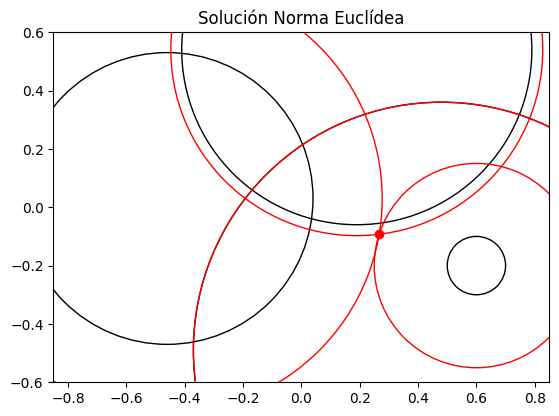

In [ ]:
#@title <font color="steelblue" size="+1"> Ejemplo  (CPLEX)
N= range(4)
D= range(2)

x=[[-0.46, 0.03]
,[0.19,0.54]
,[0.48,-0.49]
,[0.6, -0.2]]
R=[0.5,0.6,0.85,0.1]
#Modelo
mdl = Model()

#Variables
delta_vars = [mdl.continuous_var(lb=None, ub=None, name=None ) for i in N]
x_vars = [mdl.continuous_var(lb=-10., ub=None, name=None ) for i in D]
a_vars = [[mdl.continuous_var(lb=-10, ub=None, name=None ) for i in D] for i  in N]
b_vars = [mdl.continuous_var(lb=0, ub=None, name=None ) for i in N]

#Objective
mdl.minimize(  mdl.sum(delta_vars[i]**2 for i in N ) )


#Restricciones
mdl.add_constraints( x_vars[i] - x[0][i] - a_vars[0][i] == 0  for i in D)
mdl.add_constraints( x_vars[i] - x[1][i] - a_vars[1][i] == 0  for i in D)
mdl.add_constraints( x_vars[i] - x[2][i] - a_vars[2][i] == 0  for i in D)
mdl.add_constraints( x_vars[i] - x[3][i] - a_vars[3][i] == 0  for i in D)

mdl.add_constraints( delta_vars[i] + R[i] - b_vars[i] == 0  for i in N)



for i in N:
    mdl.add_constraint( a_vars[i][0]**2 + a_vars[i][1]**2  - b_vars[i]**2 <= 0   )





s = mdl.solve(log_output=True)

obj = mdl.objective_value

for i in N:
    print(" La variable d{} toma el valor {}".format(i,delta_vars[i].solution_value))


for i in D:
    print(" La variable x{} toma el valor {}".format(i,x_vars[i].solution_value))

print("* best objective is: {:g}".format(obj))

mdl.export_as_lp("Ejericio3.lp")

import matplotlib.pyplot as plt

Circunferencia1 = plt.Circle((x[0][0], x[0][1]), R[0], fill=False)
Circunferencia1_2 = plt.Circle((x[0][0], x[0][1]), R[0]+delta_vars[0].solution_value, fill=False, color="red")
Circunferencia2 = plt.Circle((x[1][0], x[1][1]), R[1], fill=False)
Circunferencia2_2 = plt.Circle((x[1][0], x[1][1]), R[1]+delta_vars[1].solution_value, fill=False, color="red")
Circunferencia3 = plt.Circle((x[2][0], x[2][1]), R[2], fill=False)
Circunferencia3_2 = plt.Circle((x[2][0], x[2][1]), R[2]+delta_vars[2].solution_value, fill=False, color="red")
Circunferencia4 = plt.Circle((x[3][0], x[3][1]), R[3], fill=False)
Circunferencia4_2 = plt.Circle((x[3][0], x[3][1]), R[3]+delta_vars[3].solution_value, fill=False, color="red")
figure, draw = plt.subplots()
draw.set_aspect(1)
draw.cla() # clear to fresh plot

plt.title('Solución Norma Euclídea')
# Set ranges
draw.set_xlim((-.85, .85))
draw.set_ylim((-.6, .6))
# Data comes here
draw.plot(x_vars[0].solution_value, x_vars[1].solution_value, marker="o", color="red")
draw.add_patch(Circunferencia1)
draw.add_patch(Circunferencia2)
draw.add_patch(Circunferencia3)
draw.add_patch(Circunferencia4)
draw.add_patch(Circunferencia1_2)
draw.add_patch(Circunferencia2_2)
draw.add_patch(Circunferencia3_2)
draw.add_patch(Circunferencia4_2)
figure.savefig('Circunferencia')
plt.show()


<font color="steelblue">**Norma $l_1$**:</font>


Considerando la norma $l_1$, la solción del problema tiende a considerar el menor número de ajustes. Este modelo tendrá sentido si un número pequeño de nuestras medidas consideramos que pueden ser medidas erróneas, proporcionadas por sensores (antenas) defectuosas.

   
Podemos ver en la solución, que aunque identifica correctamente al sensor defectuoso, también perturba el radio del sensor número 1.

   ![antenas5](https://drive.google.com/thumbnail?id=1A0FVV_ngIah7W0Ytj2z7zRlCDQNtJOmZ&sz=h450)


   

Version identifier: 22.2.0.0 | 2026-07-01 | 7cae668b4
CPXPARAM_Read_DataCheck                          1
Tried aggregator 1 time.
Aggregator did 6 substitutions.
Reduced QCP has 18 rows, 12 columns, and 24 nonzeros.
Reduced QCP has 4 quadratic constraints.
Presolve time = 0.00 sec. (0.01 ticks)
Parallel mode: using up to 2 threads for barrier.
Number of nonzeros in lower triangle of A*A' = 63
Using Approximate Minimum Degree ordering
Total time for automatic ordering = 0.00 sec. (0.00 ticks)
Summary statistics for Cholesky factor:
  Threads                   = 2
  Rows in Factor            = 18
  Integer space required    = 22
  Total non-zeros in factor = 102
  Total FP ops to factor    = 750
 Itn      Primal Obj        Dual Obj  Prim Inf Upper Inf  Dual Inf Inf Ratio
   0   3.6068542e+00  -2.0500000e+00  7.65e+01  0.00e+00  1.37e+01  1.00e+00
   1   2.3295925e+01   2.5165514e+01  7.65e+01  0.00e+00  1.37e+01  2.34e-01
   2   3.6170134e+00   3.6641825e+00  2.76e+01  0.00e+00  4.93e+00

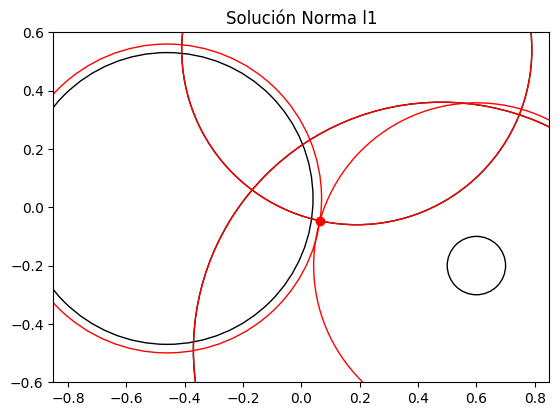

In [ ]:
#@title <font color="steelblue" size="+1"> Ejemplo cont. (CPLEX)
N= range(4)
D= range(2)

x=[[-0.46, 0.03]
,[0.19,0.54]
,[0.48,-0.49]
,[0.6, -0.2]]
R=[0.5,0.6,0.85,0.1]
#Modelo
mdl = Model()

#Variables
delta_vars = [mdl.continuous_var(lb=None, ub=None, name=None ) for i in N]
x_vars = [mdl.continuous_var(lb=-10., ub=None, name=None ) for i in D]
a_vars = [[mdl.continuous_var(lb=-10, ub=None, name=None ) for i in D] for i  in N]
b_vars = [mdl.continuous_var(lb=0, ub=None, name=None ) for i in N]

#Objective
mdl.minimize(  mdl.sum(delta_vars[i] for i in N ) )


#Restricciones
mdl.add_constraints( x_vars[i] - x[0][i] - a_vars[0][i] == 0  for i in D)
mdl.add_constraints( x_vars[i] - x[1][i] - a_vars[1][i] == 0  for i in D)
mdl.add_constraints( x_vars[i] - x[2][i] - a_vars[2][i] == 0  for i in D)
mdl.add_constraints( x_vars[i] - x[3][i] - a_vars[3][i] == 0  for i in D)

mdl.add_constraints( delta_vars[i] + R[i] - b_vars[i] == 0  for i in N)



for i in N:
    mdl.add_constraint( a_vars[i][0]**2 + a_vars[i][1]**2  - b_vars[i]**2 <= 0   )





s = mdl.solve(log_output=True)

obj = mdl.objective_value

for i in N:
    print(" La variable d{} toma el valor {}".format(i,delta_vars[i].solution_value))


for i in D:
    print(" La variable x{} toma el valor {}".format(i,x_vars[i].solution_value))

print("* best objective is: {:g}".format(obj))

mdl.export_as_lp("Ejercicio3.lp")


import matplotlib.pyplot as plt

Circunferencia1 = plt.Circle((x[0][0], x[0][1]), R[0], fill=False)
Circunferencia1_2 = plt.Circle((x[0][0], x[0][1]), R[0]+delta_vars[0].solution_value, fill=False, color="red")
Circunferencia2 = plt.Circle((x[1][0], x[1][1]), R[1], fill=False)
Circunferencia2_2 = plt.Circle((x[1][0], x[1][1]), R[1]+delta_vars[1].solution_value, fill=False, color="red")
Circunferencia3 = plt.Circle((x[2][0], x[2][1]), R[2], fill=False)
Circunferencia3_2 = plt.Circle((x[2][0], x[2][1]), R[2]+delta_vars[2].solution_value, fill=False, color="red")
Circunferencia4 = plt.Circle((x[3][0], x[3][1]), R[3], fill=False)
Circunferencia4_2 = plt.Circle((x[3][0], x[3][1]), R[3]+delta_vars[3].solution_value, fill=False, color="red")
figure, draw = plt.subplots()
draw.set_aspect(1)
draw.cla() # clear to fresh plot

plt.title('Solución Norma l1')
# Set ranges
draw.set_xlim((-.85, .85))
draw.set_ylim((-.6, .6))
# Data comes here
draw.plot(x_vars[0].solution_value, x_vars[1].solution_value, marker="o", color="red")
draw.add_patch(Circunferencia1)
draw.add_patch(Circunferencia2)
draw.add_patch(Circunferencia3)
draw.add_patch(Circunferencia4)
draw.add_patch(Circunferencia1_2)
draw.add_patch(Circunferencia2_2)
draw.add_patch(Circunferencia3_2)
draw.add_patch(Circunferencia4_2)
figure.savefig('Norma_L1')
plt.show()

